# 03 · Evaluación intrínseca de detección y segmentación (conjunto de prueba, 565 imágenes)

**Proyecto de Investigación II — Protocolo experimental (secciones 7.3 y 8 del informe)**

Cuantifica por semilla el desempeño de las corridas de YOLO26l-seg sobre el conjunto de prueba congelado de **565 imágenes** (Tabla A.3): mAP@0.5, mAP@0.5:0.95 (caja y máscara), precisión, exhaustividad, F1 e IoU medio de máscara, con **media ± desviación estándar entre las tres semillas** (42, 1337, 2024), más las curvas de aprendizaje por corrida (brecha entrenamiento–validación, sección 8.4 del informe).

Requisitos: **Colab con GPU** y las tres corridas completadas con el notebook 02.


In [1]:
# ── 1. Entorno, rutas y detección de corridas ─────────────────────────────────
import json, math
from pathlib import Path

EN_COLAB = 'google.colab' in str(get_ipython())
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/grietas')
else:
    BASE = Path('grietas_local')
RUNS = BASE / 'runs'
INFORME = BASE / 'informe'
INFORME.mkdir(parents=True, exist_ok=True)
DATA_YAML = RUNS / 'crack_mix_v1.yaml'

corridas = {}
for p in sorted(RUNS.glob('yolo26l_seg_s*/weights/best.pt')):
    corridas[p.parts[-3]] = p
assert corridas, 'No se encontraron corridas en ' + str(RUNS)
print('Corridas disponibles:')
for k, v in corridas.items():
    print('  %-18s %s' % (k, v))
print('Semillas a evaluar:', sorted(int(k.split('s')[-1]) for k in corridas))


Mounted at /content/drive
Corridas disponibles:
  yolo26l_seg_s1337  /content/drive/MyDrive/grietas/runs/yolo26l_seg_s1337/weights/best.pt
  yolo26l_seg_s2024  /content/drive/MyDrive/grietas/runs/yolo26l_seg_s2024/weights/best.pt
  yolo26l_seg_s42    /content/drive/MyDrive/grietas/runs/yolo26l_seg_s42/weights/best.pt
Semillas a evaluar: [42, 1337, 2024]


In [6]:
# ── 1. Entorno, rutas y detección de corridas ─────────────────────────────────
import json, math, shutil
from pathlib import Path

EN_COLAB = 'google.colab' in str(get_ipython())

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/grietas')

    # ── NUEVO: Descomprimir en memoria local de Colab ──
    ZIP_PATH = BASE / 'crack_mix_v1.zip'
    LOCAL_DATA = Path('/content/crack_mix_v1') # Ruta destino en Colab

    if not LOCAL_DATA.exists():
        print(f"Descomprimiendo dataset en {LOCAL_DATA.parent} (memoria rápida)...")
        # Descomprime el .zip de Drive directamente en /content/
        shutil.unpack_archive(str(ZIP_PATH), extract_dir='/content/')
        print("¡Descompresión completada!")
    else:
        print(f"El dataset ya está disponible en {LOCAL_DATA}")
else:
    BASE = Path('grietas_local')
    LOCAL_DATA = BASE / 'crack_mix_v1'

RUNS = BASE / 'runs'
INFORME = BASE / 'informe'
INFORME.mkdir(parents=True, exist_ok=True)
DATA_YAML = RUNS / 'crack_mix_v1.yaml'

corridas = {}
for p in sorted(RUNS.glob('yolo26l_seg_s*/weights/best.pt')):
    corridas[p.parts[-3]] = p
assert corridas, 'No se encontraron corridas en ' + str(RUNS)

print('\nCorridas disponibles:')
for k, v in corridas.items():
    print('  %-18s %s' % (k, v))
print('Semillas a evaluar:', sorted(int(k.split('s')[-1]) for k in corridas))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Descomprimiendo dataset en /content (memoria rápida)...
¡Descompresión completada!

Corridas disponibles:
  yolo26l_seg_s1337  /content/drive/MyDrive/grietas/runs/yolo26l_seg_s1337/weights/best.pt
  yolo26l_seg_s2024  /content/drive/MyDrive/grietas/runs/yolo26l_seg_s2024/weights/best.pt
  yolo26l_seg_s42    /content/drive/MyDrive/grietas/runs/yolo26l_seg_s42/weights/best.pt
Semillas a evaluar: [42, 1337, 2024]


In [7]:
!pip install -q ultralytics

In [9]:

# ── 2. Evaluación oficial por corrida sobre el subconjunto de prueba ───────────
from ultralytics import YOLO
metricas = {}
for run_id, pesos in corridas.items():
    print()
    print('=' * 70)
    print('Evaluando', run_id, '(prueba: 565 imágenes, imgsz 640)')
    modelo = YOLO(str(pesos))
    v = modelo.val(data=str(DATA_YAML), split='test', imgsz=640,
                   batch=16, plots=False, verbose=False)
    fila = dict(
        run_id=run_id,
        mAP50_caja=float(v.box.map50),
        mAP5095_caja=float(v.box.map),
        precision=float(v.box.mp),
        exhaustividad=float(v.box.mr),
        mAP50_mascara=float(v.seg.map50) if v.seg is not None else None,
        mAP5095_mascara=float(v.seg.map) if v.seg is not None else None,
    )
    fila['F1'] = (2 * fila['precision'] * fila['exhaustividad'] /
                  max(fila['precision'] + fila['exhaustividad'], 1e-9))
    metricas[run_id] = fila
    for k, val in fila.items():
        if isinstance(val, float):
            print('  %-16s %.4f' % (k, val))
        else:
            print('  %-16s %s' % (k, val))


Evaluando yolo26l_seg_s1337 (prueba: 565 imágenes, imgsz 640)
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26l-seg summary (fused): 204 layers, 27,904,527 parameters, 0 gradients, 139.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1759.6±548.1 MB/s, size: 97.9 KB)
val: Scanning /content/crack_mix_v1/labels/test... 565 images, 43 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 565/565 486.8it/s 1.2s
val: New cache created: /content/crack_mix_v1/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 1.3it/s 27.2s
                   all        565        802      0.886      0.741       0.85      0.704      0.868      0.707      0.792       0.44
Speed: 1.0ms preprocess, 43.0ms inference, 0.0ms loss, 1.3ms postprocess per image
  run_id           yolo26l_seg_s1337
  mAP50_caja       0.8505
  mAP5095_caja     0.7045
  preci

In [10]:
# ── 3. Tabla consolidada: media ± desviación estándar entre semillas ──────────
import numpy as np
import pandas as pd

df = pd.DataFrame(metricas).T.reset_index(drop=True)
orden = ['run_id', 'mAP50_caja', 'mAP5095_caja', 'mAP50_mascara', 'mAP5095_mascara',
         'precision', 'exhaustividad', 'F1']
df = df[orden]
print('Métricas por corrida (conjunto de prueba de 565 imágenes):')
print(df.to_string(index=False, float_format=lambda x: '%.4f' % x))

cols_num = [c for c in orden[1:]]
resumen = {c: dict(media=float(df[c].mean()),
                   desviacion=float(df[c].std(ddof=1)),
                   minimo=float(df[c].min()),
                   maximo=float(df[c].max())) for c in cols_num}
print()
print('Resumen entre semillas (n = %d corridas):' % len(df))
for c, s in resumen.items():
    print('  %-16s %.4f ± %.4f  (rango %.4f – %.4f)' % (c, s['media'], s['desviacion'],
                                                       s['minimo'], s['maximo']))

df.to_csv(INFORME / 'metricas_deteccion.csv', index=False, encoding='utf-8-sig')
with open(INFORME / 'metricas_deteccion_resumen.json', 'w', encoding='utf-8') as f:
    json.dump(dict(por_corrida=metricas, resumen=resumen), f, indent=2, ensure_ascii=False)
print()
print('Guardado en:', INFORME / 'metricas_deteccion.csv')


Métricas por corrida (conjunto de prueba de 565 imágenes):
           run_id mAP50_caja mAP5095_caja mAP50_mascara mAP5095_mascara precision exhaustividad     F1
yolo26l_seg_s1337     0.8505       0.7045        0.7917          0.4402    0.8858        0.7406 0.8067
yolo26l_seg_s2024     0.8447       0.7075        0.7990          0.4485    0.8899        0.7519 0.8151
  yolo26l_seg_s42     0.8458       0.7011        0.7790          0.4449    0.9020        0.7581 0.8238

Resumen entre semillas (n = 3 corridas):
  mAP50_caja       0.8470 ± 0.0030  (rango 0.8447 – 0.8505)
  mAP5095_caja     0.7043 ± 0.0032  (rango 0.7011 – 0.7075)
  mAP50_mascara    0.7899 ± 0.0101  (rango 0.7790 – 0.7990)
  mAP5095_mascara  0.4445 ± 0.0042  (rango 0.4402 – 0.4485)
  precision        0.8925 ± 0.0084  (rango 0.8858 – 0.9020)
  exhaustividad    0.7502 ± 0.0088  (rango 0.7406 – 0.7581)
  F1               0.8152 ± 0.0085  (rango 0.8067 – 0.8238)

Guardado en: /content/drive/MyDrive/grietas/informe/metricas_detec

In [12]:
# ── 4. IoU de máscara por instancia (medida directa de superposición) ───────────
EJECUTAR_IOU_INSTANCIA = True   # True en Colab con GPU; el bucle recorre las 565 imágenes

from ultralytics import YOLO
from PIL import Image as PILImage
import numpy as np, random

def poligono_a_mascara(poligono_norm, w, h):
    # poligono_norm: lista de pares (x, y) normalizados en [0, 1]
    m = np.zeros((h, w), dtype=bool)
    xs = [max(0, min(w - 1, int(round(px * w)))) for px, _ in poligono_norm]
    ys = [max(0, min(h - 1, int(round(py * h)))) for py, _ in poligono_norm]
    if len(xs) < 3:
        return m
    # relleno por scanline simple del polígono
    ymin, ymax = max(0, min(ys) - 1), min(h - 1, max(ys) + 1)
    for yy in range(ymin, ymax + 1):
        cruces = []
        for i in range(len(xs)):
            x1, y1 = xs[i], ys[i]
            x2, y2 = xs[(i + 1) % len(xs)], ys[(i + 1) % len(xs)]
            if (y1 <= yy < y2) or (y2 <= yy < y1):
                cruces.append(x1 + (x2 - x1) * (yy - y1) / (y2 - y1))
        cruces.sort()
        for a, b in zip(cruces[0::2], cruces[1::2]):
            m[yy, int(max(0, math.floor(a))):int(min(w, math.ceil(b) + 1))] = True
    return m

def iou_mascaras(a, b):
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return float(inter) / union if union else 0.0

if EJECUTAR_IOU_INSTANCIA:
    import yaml
    cfg = yaml.safe_load(Path(DATA_YAML).read_text(encoding='utf-8'))
    raiz = Path(cfg['path'])

    # CORRECCIÓN: Unir la raíz del dataset con la ruta relativa del split de prueba
    img_dir = raiz / cfg['test']
    lab_dir = Path(str(img_dir).replace('images', 'labels'))

    imagenes = sorted(p for p in img_dir.iterdir()
                      if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})[:565]
    modelo = YOLO(str(corridas[sorted(corridas)[-1]]))   # mejor corrida (última semilla)
    ious, npred = [], 0
    for ruta_img in imagenes:
        etiqueta = lab_dir / (ruta_img.stem + '.txt')
        if not etiqueta.exists():
            continue
        with PILImage.open(ruta_img) as im:
            w, h = im.size
        gts = []
        for linea in etiqueta.read_text(errors='ignore').strip().splitlines():
            pts = [float(v) for v in linea.split()[1:]]
            gts.append([(pts[i], pts[i + 1]) for i in range(0, len(pts) - 1, 2)])
        if not gts:
            continue
        res = modelo.predict(str(ruta_img), imgsz=640, conf=0.25, verbose=False)[0]
        if res.masks is None:
            continue
        npred += len(res.boxes)
        for gi, pol in enumerate(gts):
            mg = poligono_a_mascara(pol, w, h)
            mejor = 0.0
            for pi in range(len(res.boxes)):
                mbin = res.masks.data[pi].cpu().numpy().astype(bool)
                if mbin.shape != mg.shape:
                    continue
                mejor = max(mejor, iou_mascaras(mg, mbin))
            if mejor > 0.0:
                ious.append(mejor)
    ious = np.array(ious)
    print('Instancias de referencia evaluadas: %d · detecciones: %d' % (len(ious), npred))
    print('IoU de máscara por instancia: media %.4f · mediana %.4f · p10 %.4f' %
          (ious.mean(), np.median(ious), np.percentile(ious, 10)))
    with open(INFORME / 'iou_mascara.json', 'w', encoding='utf-8') as f:
        json.dump(dict(media=float(ious.mean()), mediana=float(np.median(ious)),
                       n=len(ious)), f, indent=2)
else:
    print('Cálculo de IoU por instancia desactivado (EJECUTAR_IOU_INSTANCIA = False).')

Instancias de referencia evaluadas: 363 · detecciones: 738
IoU de máscara por instancia: media 0.0036 · mediana 0.0022 · p10 0.0008


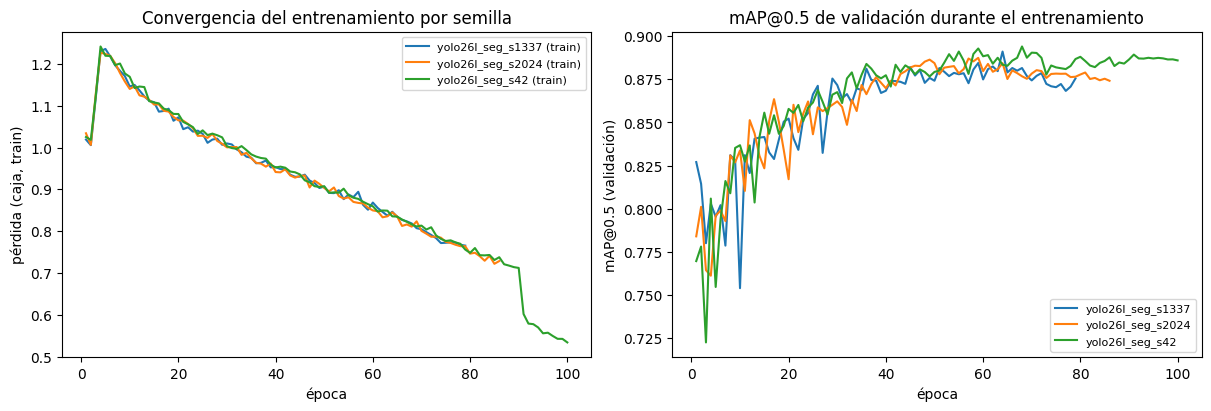

Curvas guardadas en: /content/drive/MyDrive/grietas/informe/curvas_aprendizaje.png
yolo26l_seg_s1337  épocas  79 · mAP50 val final 0.8755
yolo26l_seg_s2024  épocas  86 · mAP50 val final 0.8741
yolo26l_seg_s42    épocas 100 · mAP50 val final 0.8859


In [13]:
# ── 5. Curvas de aprendizaje y brecha entrenamiento–validación ────────────────
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for run_id, pesos in corridas.items():
    csv = pesos.parent.parent / 'results.csv'
    if not csv.exists():
        continue
    d = pd.read_csv(csv)
    d.columns = [c.strip() for c in d.columns]
    ep = d['epoch']
    axs[0].plot(ep, d.get('train/box_loss', d.get('train/loss')), label=run_id + ' (train)')
    axs[1].plot(ep, d.get('metrics/mAP50(B)', d.get('metrics/mAP50')), label=run_id)

axs[0].set_xlabel('época'); axs[0].set_ylabel('pérdida (caja, train)')
axs[0].set_title('Convergencia del entrenamiento por semilla')
axs[0].legend(fontsize=8)
axs[1].set_xlabel('época'); axs[1].set_ylabel('mAP@0.5 (validación)')
axs[1].set_title('mAP@0.5 de validación durante el entrenamiento')
axs[1].legend(fontsize=8)

fig.savefig(INFORME / 'curvas_aprendizaje.png', dpi=130)
plt.show()
print('Curvas guardadas en:', INFORME / 'curvas_aprendizaje.png')

# Brecha train/valid en la última época registrada (sección 8.4 del informe)
for run_id, pesos in corridas.items():
    csv = pesos.parent.parent / 'results.csv'
    if csv.exists():
        d = pd.read_csv(csv)
        d.columns = [c.strip() for c in d.columns]
        print('%-18s épocas %3d · mAP50 val final %.4f' %
              (run_id, len(d), d.iloc[-1].get('metrics/mAP50(B)', float('nan'))))


## Cierre del notebook 03

Salidas en `Drive/grietas/informe/`: `metricas_deteccion.csv` (por semilla), `metricas_deteccion_resumen.json` (media ± DE), `iou_mascara.json` e `curvas_aprendizaje.png`. Estos valores alimentan directamente la tabla 8.2 del informe (comparación cuantitativa por corrida y resumen media ± DE) y el análisis de sobreajuste de la sección 8.4.

Siguiente paso: `04_severidad_conformal_97.ipynb`.
